In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import bootstrap
import numpy as np
plt.style.use('seaborn-v0_8-whitegrid')

In [2]:
linear11 = pd.read_csv('linear11/results/evaluation.csv')
convex11 = pd.read_csv('convex11/results/evaluation.csv')
concave11 = pd.read_csv('concave11/results/evaluation.csv')
linear21 = pd.read_csv('linear21/results/evaluation.csv')
convex21 = pd.read_csv('convex21/results/evaluation.csv')
concave21 = pd.read_csv('concave21/results/evaluation.csv')
linear31 = pd.read_csv('linear31/results/evaluation.csv')
convex31 = pd.read_csv('convex31/results/evaluation.csv')
concave31 = pd.read_csv('concave31/results/evaluation.csv')
linear41 = pd.read_csv('linear41/results/evaluation.csv')
convex41 = pd.read_csv('convex41/results/evaluation.csv')
concave41 = pd.read_csv('concave41/results/evaluation.csv')

In [3]:
baseline = linear11['Stage 0'].median()

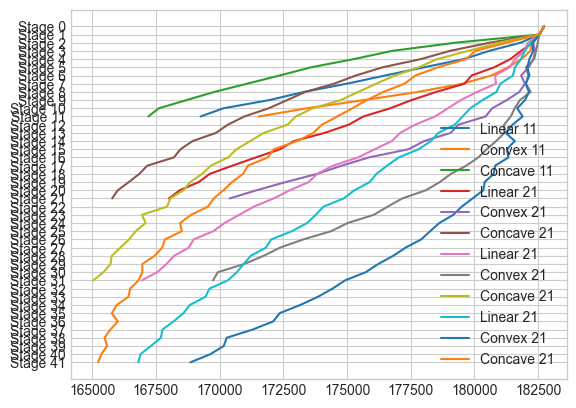

In [4]:
plt.plot(linear11.median().values, linear11.median().index, label='Linear 11')
plt.plot(convex11.median().values, convex11.median().index, label='Convex 11')
plt.plot(concave11.median().values, concave11.median().index, label='Concave 11')

plt.plot(linear21.median().values, linear21.median().index, label='Linear 21')
plt.plot(convex21.median().values, convex21.median().index, label='Convex 21')
plt.plot(concave21.median().values, concave21.median().index, label='Concave 21')

plt.plot(linear31.median().values, linear31.median().index, label='Linear 21')
plt.plot(convex31.median().values, convex31.median().index, label='Convex 21')
plt.plot(concave31.median().values, concave31.median().index, label='Concave 21')

plt.plot(linear41.median().values, linear41.median().index, label='Linear 21')
plt.plot(convex41.median().values, convex41.median().index, label='Convex 21')
plt.plot(concave41.median().values, concave41.median().index, label='Concave 21')

plt.gca().invert_yaxis()
plt.legend()

In [5]:
def get_med_ci(data):
    median = ((baseline - data.median()) / data.median()) * 100
    res = bootstrap(
        (((baseline - data) / data) * 100,), np.median, axis=0, confidence_level=0.95, n_resamples=10000
    )
    ci_low, ci_high = res.confidence_interval
    return median, median - ci_low, ci_high - median

In [6]:
linears = [linear11, linear21, linear31, linear41]
convexs = [convex11, convex21, convex31, convex41]
concaves = [concave11, concave21, concave31, concave41]

yerrs_linear = [[], []]
medians_linear = []
for z in linears:
    m, cil, cih = get_med_ci(z[z.columns[-1]])
    medians_linear.append(m)
    yerrs_linear[0].append(cil)
    yerrs_linear[1].append(cih)

yerrs_convex = [[], []]
medians_convex = []
for z in convexs:
    m, cil, cih = get_med_ci(z[z.columns[-1]])
    medians_convex.append(m)
    yerrs_convex[0].append(cil)
    yerrs_convex[1].append(cih)

yerrs_concave = [[], []]
medians_concave = []
for z in concaves:
    m, cil, cih = get_med_ci(z[z.columns[-1]])
    medians_concave.append(m)
    yerrs_concave[0].append(cil)
    yerrs_concave[1].append(cih)

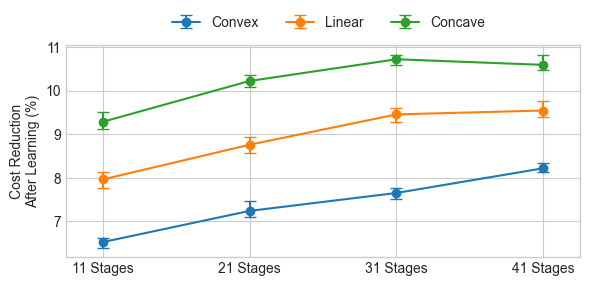

In [7]:
fig, ax = plt.subplots(1, figsize=(6, 3))
ax.errorbar(range(4), medians_convex, yerr=yerrs_convex, fmt="-o", capsize=4, label="Convex")
ax.errorbar(range(4), medians_linear, yerr=yerrs_linear, fmt="-o", capsize=4, label="Linear")
ax.errorbar(range(4), medians_concave, yerr=yerrs_concave, fmt="-o", capsize=4, label="Concave")
# ax.plot([((baseline - v) / baseline) * 100 for v in [c.median().min() for c in convexs]], label='Convex', marker='o')
# ax.plot([((baseline - v) / baseline) * 100 for v in [c.median().min() for c in linears]], label='Linear', marker='o')
# ax.plot([((baseline - v) / baseline) * 100 for v in [c.median().min() for c in concaves]], label='Concave', marker='o')
ax.set_xticks([0, 1, 2, 3])
ax.set_xticklabels(['11 Stages', '21 Stages', '31 Stages', '41 Stages'])
ax.set_xlim(-0.25, 3.25)
ax.set_ylabel("Cost Reduction\nAfter Learning (%)")
plt.legend(ncol=3, bbox_to_anchor=(0.84, 1.2))
plt.tight_layout()
plt.show()